# Constraint and Probability-Distribution Validation

This notebook validates the implemented demographic and behavioural constraints in the human-mobility representation framework. The integrated Behavioural Evidence Layer is tested as one input, and its trip-purpose, start-time and travel-mode distributions are checked within the same framework execution.

The numerical validation follows one consistent comparison:

**source distribution → independently calculated expected distribution → framework output**

A PASS requires the framework output to match the independently calculated expected distribution within an absolute tolerance of `1e-8`. The notebook validates every retained representative-profile row through its exact combination of output-relevant attributes; identical combinations are executed once and the result is assigned back to every matching row.

This is an implementation validation. It does not assess whether the NTS estimates or the selected behavioural assumptions are complete descriptions of real-world behaviour.

## Validation groups and expected outcomes

| Validation group | Constraint condition | Expected outcome |
|---|---|---|
| Profiles without profile-specific constraints | No profile-specific constraint condition is met | The trip-purpose distribution matches the original NTS0611a distribution. |
| Profiles with trip-purpose constraints | `Industry = Does not apply` | `Commuting` and `Business` are removed; remaining probabilities are renormalised. |
| Profiles with trip-purpose constraints | Distance travelled to work = `Works mainly from home` | `Commuting` is removed; remaining probabilities are renormalised. |
| Profiles with travel-mode constraints | Age is `0–4` or `5–11` | `Car or van driver` and `Motorcycle` are removed; remaining probabilities are renormalised. |
| Profiles with travel-mode constraints | No household car | `Car or van driver` and `Car or van passenger` are removed; remaining probabilities are renormalised. |
| Profiles with multiple profile-specific constraints | More than one profile-specific constraint condition is met | All applicable removals are applied together and remaining probabilities are renormalised. |

**Study-area condition.** For the Manchester case study, `Bus in London` and `London Underground` are removed from the travel-mode distributions of all profiles, and remaining probabilities are renormalised.

**Unaffected distribution.** Start-time distributions are not modified by any implemented constraint and must match the original NTS0502b distribution for every retained trip purpose.

The rule-level groups can overlap. For example, a young profile can also have `Industry = Does not apply`. Every representative profile row is tested, while the figures later in the notebook show selected representative cases.

## AI Collaboration Record

**Human author and reviewer:** Peter Jiang  
**AI tool:** OpenAI Codex  
**Date:** 18 August 2026  
**Scope:** Notebook structure, Python implementation, validation logic, plots, code comments and documentation.  
**Human responsibility:** Review the rules against the dissertation methodology and repository, run the notebook on the final project outputs, inspect failures and figures, and approve the interpretation used in the dissertation.

### Consolidated prompt

> Create a Jupyter notebook for the mobility-modelling framework that validates every retained representative profile against the implemented constraints. Use the following validation groups: profiles without profile-specific constraints; profiles where Industry equals Does not apply; profiles working mainly from home; young profiles aged 0–4 or 5–11; profiles with no household car; and profiles with multiple profile-specific constraints. Apply the Manchester study-area removal of Bus in London and London Underground to every profile. Load the integrated `nts_behavioural_evidence_layer.json` as the framework evidence being tested, while retaining the three harmonised NTS files only as independent reference distributions. Validate NTS0611a trip-purpose, NTS0502b start-time and NTS0409a travel-mode distributions in the same framework execution. For each unique output-relevant input combination, independently calculate the expected distribution without calling the framework constraint functions, execute the framework, compare categories and probabilities within an absolute tolerance of `1e-8`, and assign the result back to every matching profile row. Report the total representative profile rows, tested rows and rows with violations using plain labels. Produce three sets of representative-case figures: three trip-purpose cases, one unchanged start-time case, and three travel-mode cases. Use only the reference distribution and framework output in the figures; retain the independently calculated expected distributions in the numerical validation. Include clear Markdown documentation and an AI Collaboration Record in every AI-generated code cell.

This consolidated English prompt records the requirements developed through the preceding Chinese-language dissertation discussion; it is not presented as a verbatim single-message quotation.

## 1. Imports and configuration

Run this notebook from `notebooks/validation`. The profile-space path, integrated behavioural-evidence path and validation-output directory can be overridden with the environment variables `PROFILE_SPACE_PATH`, `BEHAVIOURAL_EVIDENCE_PATH` and `VALIDATION_OUTPUT_DIR` when required.

In [1]:
# AI Collaboration Record
# Tool: OpenAI Codex
# Human author and reviewer: Peter Jiang
# Prompt reference: See "AI Collaboration Record" near the start of this notebook.
# Prompt summary: Import the required libraries, locate the repository root and define reproducible input and output paths.

import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd


TOLERANCE = 1e-8

project_root = Path.cwd().parents[1]
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

profile_space_path = Path(
    os.environ.get(
        "PROFILE_SPACE_PATH",
        project_root
        / "output"
        / "representative_profiles"
        / "constrained_representative_profile_space.parquet",
    )
)

harmonised_nts_directory = (
    project_root / "data" / "nts" / "harmonised"
)

behavioural_evidence_path = Path(
    os.environ.get(
        "BEHAVIOURAL_EVIDENCE_PATH",
        project_root
        / "output"
        / "behavioural_evidence"
        / "nts_behavioural_evidence_layer.json",
    )
)

validation_output_directory = Path(
    os.environ.get(
        "VALIDATION_OUTPUT_DIR",
        project_root
        / "output"
        / "validation"
        / "constraint_distribution_validation",
    )
)
figure_output_directory = validation_output_directory / "figures"

validation_output_directory.mkdir(parents=True, exist_ok=True)
figure_output_directory.mkdir(parents=True, exist_ok=True)

print("Project root:", project_root)
print("Profile-space input:", profile_space_path)
print("Integrated behavioural-evidence input:", behavioural_evidence_path)
print("Validation output:", validation_output_directory)

Project root: c:\Users\user\OneDrive - University of Stirling\Desktop\dissertation\mobility-modelling-framework
Profile-space input: c:\Users\user\OneDrive - University of Stirling\Desktop\dissertation\mobility-modelling-framework\output\representative_profiles\constrained_representative_profile_space.parquet
Integrated behavioural-evidence input: c:\Users\user\OneDrive - University of Stirling\Desktop\dissertation\mobility-modelling-framework\output\behavioural_evidence\nts_behavioural_evidence_layer.json
Validation output: c:\Users\user\OneDrive - University of Stirling\Desktop\dissertation\mobility-modelling-framework\output\validation\constraint_distribution_validation


## 2. Load current framework inputs

The notebook reads the current constrained profile-space output and the integrated Behavioural Evidence Layer output. The three harmonised NTS files are also loaded, but only as independent sources for calculating the expected distributions. Run the upstream construction notebooks first if any required output is missing.

In [2]:
# AI Collaboration Record
# Tool: OpenAI Codex
# Human author and reviewer: Peter Jiang
# Prompt reference: See "AI Collaboration Record" near the start of this notebook.
# Prompt summary: Load the constrained profile space, integrated Behavioural Evidence Layer and three harmonised NTS reference tables, then import the framework integration function.

required_paths = {
    "Constrained representative profile space": profile_space_path,
    "Integrated behavioural evidence": behavioural_evidence_path,
    "NTS0611a": (
        harmonised_nts_directory
        / "nts0611a_trip_purpose_probability.json"
    ),
    "NTS0502b": (
        harmonised_nts_directory
        / "nts0502b_trip_start_time_probability.json"
    ),
    "NTS0409a": (
        harmonised_nts_directory
        / "nts0409a_travel_mode_probability.json"
    ),
}

missing_paths = [
    f"{name}: {path}"
    for name, path in required_paths.items()
    if not path.exists()
]
if missing_paths:
    raise FileNotFoundError(
        "Run the upstream construction notebooks before this validation:\n"
        + "\n".join(missing_paths)
    )

representative_profile_space = pd.read_parquet(profile_space_path)
with open(
    required_paths["Integrated behavioural evidence"],
    "r",
    encoding="utf-8",
) as behavioural_evidence_file:
    assembled_behavioural_evidence = json.load(
        behavioural_evidence_file
    )

nts0611_df = pd.read_json(required_paths["NTS0611a"])
nts0502_df = pd.read_json(required_paths["NTS0502b"])
nts0409_df = pd.read_json(required_paths["NTS0409a"])

from ontology.NTS_TRIP_PURPOSE_MAPPING import NTS_TRIP_PURPOSE_MAPPING
from ontology.STUDY_AREA import STUDY_AREA
from src.demographic_behaviour_layers_integration import (
    DEMOGRAPHIC_ATTRIBUTES,
    construct_constrained_behaviour_representation,
)

print(
    "Retained representative profiles loaded:",
    f"{len(representative_profile_space):,}",
)
print(
    "Framework trip purposes loaded from the integrated layer:",
    len(assembled_behavioural_evidence),
)
print("Configured study area:", STUDY_AREA)

Retained representative profiles loaded: 2,147,608
Framework trip purposes loaded from the integrated layer: 14
Configured study area: Manchester


## 3. Validate the integrated Behavioural Evidence Layer structure

The integrated JSON is the Behavioural Evidence Layer used by the framework. This section checks that it includes the same 14 framework trip purposes as NTS0611a and that each trip purpose contains the three required behavioural components. The expected constraint outcomes are still calculated independently from the harmonised NTS reference files in Section 6.

In [3]:
# AI Collaboration Record
# Tool: OpenAI Codex
# Human author and reviewer: Peter Jiang
# Prompt reference: See "AI Collaboration Record" near the start of this notebook.
# Prompt summary: Confirm that the integrated Behavioural Evidence Layer contains every framework trip purpose and all three required probability components.

PURPOSE_EVIDENCE_KEY = "nts0611a_trip_purpose_distribution"
TIME_EVIDENCE_KEY = "nts0502b_trip_start_time_distribution"
MODE_EVIDENCE_KEY = "nts0409a_travel_mode_distribution"

trip_purpose_categories = [
    column
    for column in nts0611_df.columns
    if column not in {"Year", "Sex", "Age"}
]

expected_purposes = set(trip_purpose_categories)
integrated_purposes = set(assembled_behavioural_evidence)
missing_purposes = sorted(
    expected_purposes - integrated_purposes
)
unexpected_purposes = sorted(
    integrated_purposes - expected_purposes
)
if missing_purposes or unexpected_purposes:
    raise ValueError(
        "Integrated behavioural evidence has inconsistent "
        f"trip purposes. Missing: {missing_purposes}; "
        f"unexpected: {unexpected_purposes}."
    )

required_evidence_keys = {
    PURPOSE_EVIDENCE_KEY,
    TIME_EVIDENCE_KEY,
    MODE_EVIDENCE_KEY,
}
expected_record_counts = {
    PURPOSE_EVIDENCE_KEY: len(nts0611_df),
    TIME_EVIDENCE_KEY: 1,
    MODE_EVIDENCE_KEY: 1,
}
structure_records = []

for purpose in trip_purpose_categories:
    evidence = assembled_behavioural_evidence[purpose]
    missing_components = sorted(
        required_evidence_keys - set(evidence)
    )
    if missing_components:
        raise KeyError(
            f"{purpose} is missing behavioural components: "
            f"{missing_components}"
        )

    record_counts = {
        key: len(evidence[key])
        for key in required_evidence_keys
        if isinstance(evidence[key], list)
    }
    non_list_components = sorted(
        key
        for key in required_evidence_keys
        if not isinstance(evidence[key], list)
    )
    if non_list_components:
        raise TypeError(
            f"{purpose} has components that are not record lists: "
            f"{non_list_components}"
        )
    incorrect_record_counts = {
        key: {
            "expected": expected_record_counts[key],
            "found": record_counts[key],
        }
        for key in required_evidence_keys
        if record_counts[key] != expected_record_counts[key]
    }
    if incorrect_record_counts:
        raise ValueError(
            f"{purpose} has incorrect behavioural record counts: "
            f"{incorrect_record_counts}"
        )

    structure_records.append(
        {
            "Framework trip purpose": purpose,
            "NTS0611a age-sex records": record_counts[
                PURPOSE_EVIDENCE_KEY
            ],
            "NTS0502b start-time records": record_counts[
                TIME_EVIDENCE_KEY
            ],
            "NTS0409a travel-mode records": record_counts[
                MODE_EVIDENCE_KEY
            ],
        }
    )

behavioural_evidence_structure = pd.DataFrame(
    structure_records
)
display(behavioural_evidence_structure)

print(
    "PASS: Integrated Behavioural Evidence Layer contains",
    len(assembled_behavioural_evidence),
    "framework trip purposes and all three required components.",
)

,Framework trip purpose,NTS0611a age-sex records,NTS0502b start-time records,NTS0409a travel-mode records
0,Commuting,18,1,1
1,Business,18,1,1
2,Education,18,1,1
3,Escort Education,18,1,1
4,Shopping,18,1,1
5,Other Escort,18,1,1
6,Personal Business,18,1,1
7,Visiting Friends at Private Home,18,1,1
8,Visiting Friends Elsewhere,18,1,1
9,Entertainment or Public Activity,18,1,1


PASS: Integrated Behavioural Evidence Layer contains 14 framework trip purposes and all three required components.


## 4. Demographic constraint validation

This preliminary check validates the two demographic constraints reported in the methodology:

1. every retained row has a non-zero value in all eight source-count columns; and
2. employed and non-employed profiles use the required Industry and Distance-to-work values.

The check validates the already constructed profile space; it does not reconstruct it.

In [4]:
# AI Collaboration Record
# Tool: OpenAI Codex
# Human author and reviewer: Peter Jiang
# Prompt reference: See "AI Collaboration Record" near the start of this notebook.
# Prompt summary: Check every retained row against the zero-count and employment constraints and report any violations.

COUNT_COLUMNS = [
    "Age Population",
    "Sex Population",
    "Household Count",
    "Economic Count",
    "Industry Count",
    "Ethnic Count",
    "Travel Distance Count",
    "Car Ownership Count",
]

EMPLOYED_PROFILES = {
    "Economically active (excluding full-time students): In employment",
    "Economically active and a full-time student: In employment",
}
DOES_NOT_APPLY = "Does not apply"

missing_profile_columns = sorted(
    set(DEMOGRAPHIC_ATTRIBUTES + tuple(COUNT_COLUMNS))
    - set(representative_profile_space.columns)
)
if missing_profile_columns:
    raise KeyError(
        "Profile space is missing required columns: "
        f"{missing_profile_columns}"
    )

zero_count_violation = ~(
    representative_profile_space[COUNT_COLUMNS]
    .notna()
    .all(axis=1)
    & representative_profile_space[COUNT_COLUMNS]
    .gt(0)
    .all(axis=1)
)

is_employed = representative_profile_space[
    "Economic Activity Status"
].isin(EMPLOYED_PROFILES)
industry_applies = representative_profile_space["Industry"].ne(
    DOES_NOT_APPLY
)
work_distance_applies = representative_profile_space[
    "Distance travelled to work"
].ne(DOES_NOT_APPLY)

employment_constraint_passed = (
    is_employed & industry_applies & work_distance_applies
) | (
    ~is_employed & ~industry_applies & ~work_distance_applies
)
employment_violation = ~employment_constraint_passed

demographic_validation_summary = pd.DataFrame(
    [
        {
            "Demographic check": "Zero-count constraint",
            "Rows checked": len(representative_profile_space),
            "Violations": int(zero_count_violation.sum()),
        },
        {
            "Demographic check": "Employment constraint",
            "Rows checked": len(representative_profile_space),
            "Violations": int(employment_violation.sum()),
        },
    ]
)
demographic_validation_summary["Result"] = np.where(
    demographic_validation_summary["Violations"].eq(0),
    "PASS",
    "FAIL",
)

display(demographic_validation_summary)

if demographic_validation_summary["Result"].eq("FAIL").any():
    raise AssertionError(
        "The imported profile space violates one or more reported "
        "demographic constraints."
    )

,Demographic check,Rows checked,Violations,Result
0,Zero-count constraint,2147608,0,PASS
1,Employment constraint,2147608,0,PASS


## 5. Identify the constraints triggered by every profile

The four profile-specific conditions are recorded independently. A profile can appear in more than one validation group. The exact combination of conditions defines its behavioural validation case. The Manchester study-area condition applies to every profile and is not included in the profile-specific constraint count.

In [5]:
# AI Collaboration Record
# Tool: OpenAI Codex
# Human author and reviewer: Peter Jiang
# Prompt reference: See "AI Collaboration Record" near the start of this notebook.
# Prompt summary: Tag every representative profile with its applicable behavioural rules, count the rows in each validation group and create exact behavioural cases.

YOUNG_AGES = {"0-4", "5-11"}
NO_HOUSEHOLD_CAR = "No cars or vans in household"

profile_validation = pd.DataFrame(
    index=representative_profile_space.index
)
profile_validation["Profile Row Position"] = np.arange(
    len(representative_profile_space),
    dtype=np.int64,
)
profile_validation["Age"] = representative_profile_space["Age"]
profile_validation["Sex"] = representative_profile_space["Sex"]
profile_validation["Industry constraint"] = (
    representative_profile_space["Industry"].eq(DOES_NOT_APPLY)
)
profile_validation["WFH constraint"] = (
    representative_profile_space[
        "Distance travelled to work"
    ].eq("Works mainly from home")
)
profile_validation["Children constraint"] = (
    representative_profile_space["Age"].isin(YOUNG_AGES)
)
profile_validation["No-car constraint"] = (
    representative_profile_space["Car Ownership"].eq(
        NO_HOUSEHOLD_CAR
    )
)

rule_columns = [
    "Industry constraint",
    "WFH constraint",
    "Children constraint",
    "No-car constraint",
]
profile_validation["Profile-specific constraint count"] = (
    profile_validation[rule_columns].sum(axis=1).astype("int8")
)

constraint_labels = pd.Series(
    "",
    index=profile_validation.index,
    dtype="string",
)
for rule_column, rule_label in {
    "Industry constraint": "Industry does not apply",
    "WFH constraint": "Works mainly from home",
    "Children constraint": "Age 0-4 or 5-11",
    "No-car constraint": "No household car",
}.items():
    applies = profile_validation[rule_column]
    separator = constraint_labels.ne("").map(
        {True: " + ", False: ""}
    )
    constraint_labels = constraint_labels + np.where(
        applies,
        separator + rule_label,
        "",
    )

profile_validation["Constraint combination"] = (
    constraint_labels.replace(
        "",
        "No profile-specific constraint",
    )
)

case_columns = ["Age", "Sex", *rule_columns]
profile_validation["Validation case"] = (
    profile_validation.groupby(
        case_columns,
        sort=False,
        dropna=False,
    ).ngroup()
)

condition_masks = {
    "No profile-specific constraint": (
        profile_validation[
            "Profile-specific constraint count"
        ].eq(0)
    ),
    "Industry = Does not apply": profile_validation[
        "Industry constraint"
    ],
    "Works mainly from home": profile_validation["WFH constraint"],
    "Age is 0-4 or 5-11": profile_validation[
        "Children constraint"
    ],
    "No household car": profile_validation["No-car constraint"],
    "Multiple profile-specific constraints": (
        profile_validation[
            "Profile-specific constraint count"
        ].gt(1)
    ),
}

condition_counts = pd.DataFrame(
    [
        {
            "Validation condition": name,
            "Representative profile rows": int(mask.sum()),
            "Percentage of representative profiles": (
                float(mask.mean() * 100)
            ),
        }
        for name, mask in condition_masks.items()
    ]
)
condition_counts.loc[len(condition_counts)] = {
    "Validation condition": "Manchester study-area constraint",
    "Representative profile rows": len(profile_validation),
    "Percentage of representative profiles": 100.0,
}

display(condition_counts)

required_condition_names = [
    "No profile-specific constraint",
    "Industry = Does not apply",
    "Works mainly from home",
    "Age is 0-4 or 5-11",
    "No household car",
    "Multiple profile-specific constraints",
]
missing_conditions = condition_counts.loc[
    condition_counts["Validation condition"].isin(
        required_condition_names
    )
    & condition_counts["Representative profile rows"].eq(0),
    "Validation condition",
].tolist()
if missing_conditions:
    raise AssertionError(
        "The current profile space contains no rows for: "
        f"{missing_conditions}"
    )

,Validation condition,Representative profile rows,Percentage of representative profiles
0,No profile-specific constraint,1357056,63.189185
1,Industry = Does not apply,36632,1.705712
2,Works mainly from home,301568,14.042041
3,Age is 0-4 or 5-11,1520,0.070776
4,No household car,536902,25.000000
5,Multiple profile-specific constraints,85690,3.990021
6,Manchester study-area constraint,2147608,100.000000


## 6. Independent expected-distribution functions

These functions reproduce the documented expected outcomes without importing or calling `apply_trip_purpose_constraint` or `apply_travel_mode_constraint`. This separation avoids validating the framework with the same implementation that produced its output.

In [6]:
# AI Collaboration Record
# Tool: OpenAI Codex
# Human author and reviewer: Peter Jiang
# Prompt reference: See "AI Collaboration Record" near the start of this notebook.
# Prompt summary: Define independent source lookups, expected category removals, renormalisation and numerical distribution comparison helpers.

SOURCE_IDENTIFIER_COLUMNS = {
    "nts0611a": {"Year", "Sex", "Age"},
    "nts0502b": {"Year", "Trip purpose"},
    "nts0409a": {"Year", "Purpose"},
}
LONDON_MODES_FOR_VALIDATION = {
    "Bus in London",
    "London Underground",
}


def numeric_distribution(dataset_row, identifier_columns):
    probability_columns = [
        column
        for column in dataset_row.index
        if column not in identifier_columns
    ]
    return pd.to_numeric(
        dataset_row[probability_columns],
        errors="raise",
    ).astype(float)


def get_one_row(dataframe, mask, description):
    rows = dataframe.loc[mask]
    if len(rows) != 1:
        raise ValueError(
            f"Expected one source row for {description}; "
            f"found {len(rows)}."
        )
    return rows.iloc[0]


def source_trip_purpose_distribution(age, sex):
    row = get_one_row(
        nts0611_df,
        nts0611_df["Age"].eq(age)
        & nts0611_df["Sex"].eq(sex),
        f"NTS0611a age={age}, sex={sex}",
    )
    return numeric_distribution(
        row,
        SOURCE_IDENTIFIER_COLUMNS["nts0611a"],
    )


def source_time_and_mode_distributions(purpose):
    mapping = NTS_TRIP_PURPOSE_MAPPING[purpose]
    temporal_purpose = mapping["nts0502b"][0]
    mode_purpose = mapping["nts0409a"][0]

    temporal_row = get_one_row(
        nts0502_df,
        nts0502_df["Trip purpose"].eq(temporal_purpose),
        f"NTS0502b purpose={temporal_purpose}",
    )
    mode_row = get_one_row(
        nts0409_df,
        nts0409_df["Purpose"].eq(mode_purpose),
        f"NTS0409a purpose={mode_purpose}",
    )

    temporal = numeric_distribution(
        temporal_row,
        SOURCE_IDENTIFIER_COLUMNS["nts0502b"],
    )
    mode = numeric_distribution(
        mode_row,
        SOURCE_IDENTIFIER_COLUMNS["nts0409a"],
    )
    return temporal, mode


def independently_expected_purpose_removals(profile):
    if profile["Industry"] == DOES_NOT_APPLY:
        return {"Commuting", "Business"}
    if (
        profile["Distance travelled to work"]
        == "Works mainly from home"
    ):
        return {"Commuting"}
    return set()


def independently_expected_mode_removals(profile):
    removals = set()

    if STUDY_AREA.strip().casefold() != "london":
        removals.update(LONDON_MODES_FOR_VALIDATION)

    if profile["Age"] in YOUNG_AGES:
        removals.update({"Car or van driver", "Motorcycle"})

    if profile["Car Ownership"] == NO_HOUSEHOLD_CAR:
        removals.update(
            {"Car or van driver", "Car or van passenger"}
        )

    return removals


def remove_and_renormalise(source_distribution, removals):
    source_distribution = pd.Series(
        source_distribution,
        dtype=float,
    )
    missing = set(removals) - set(source_distribution.index)
    if missing:
        raise KeyError(
            "Expected removal categories are missing from the source "
            f"distribution: {sorted(missing)}"
        )

    if not removals:
        return source_distribution.copy()

    retained = source_distribution.drop(labels=list(removals))
    retained_total = float(retained.sum())
    if retained.empty or retained_total <= 0:
        raise ValueError(
            "No positive probability remains after the expected "
            "category removals."
        )
    return retained / retained_total


def compare_distributions(expected, actual):
    expected = pd.Series(expected, dtype=float)
    actual = pd.Series(actual, dtype=float)

    categories_match = set(expected.index) == set(actual.index)
    actual_aligned = actual.reindex(expected.index)

    if categories_match:
        differences = (expected - actual_aligned).abs()
        maximum_difference = (
            float(differences.max())
            if not differences.empty
            else 0.0
        )
        probabilities_match = bool(
            np.allclose(
                expected.to_numpy(dtype=float),
                actual_aligned.to_numpy(dtype=float),
                rtol=0.0,
                atol=TOLERANCE,
                equal_nan=False,
            )
        )
    else:
        maximum_difference = np.inf
        probabilities_match = False

    expected_values = expected.to_numpy(dtype=float)
    actual_values = actual.to_numpy(dtype=float)
    values_are_valid = bool(
        np.isfinite(expected_values).all()
        and np.isfinite(actual_values).all()
        and (expected_values >= 0).all()
        and (actual_values >= 0).all()
    )
    sums_are_valid = bool(
        np.isclose(
            expected.sum(),
            1.0,
            rtol=0.0,
            atol=TOLERANCE,
        )
        and np.isclose(
            actual.sum(),
            1.0,
            rtol=0.0,
            atol=TOLERANCE,
        )
    )

    return {
        "Categories match": categories_match,
        "Probabilities match": probabilities_match,
        "Values valid": values_are_valid,
        "Probability sums valid": sums_are_valid,
        "Maximum absolute difference": maximum_difference,
        "Expected probability sum": float(expected.sum()),
        "Framework probability sum": float(actual.sum()),
        "Result": (
            "PASS"
            if categories_match
            and probabilities_match
            and values_are_valid
            and sums_are_valid
            else "FAIL"
        ),
    }

## 7. Execute every unique behavioural input combination

`Age` and `Sex` determine the NTS0611a lookup. The four Boolean rule indicators determine every implemented profile-specific constraint branch. The framework is therefore executed once for each unique combination of these fields, and the passed result is assigned to every matching row.

For every retained trip purpose, NTS0502b is expected to remain unchanged and NTS0409a is expected to reflect the union of the global Manchester removals and any applicable profile-specific mode removals.

In [7]:
# AI Collaboration Record
# Tool: OpenAI Codex
# Human author and reviewer: Peter Jiang
# Prompt reference: See "AI Collaboration Record" near the start of this notebook.
# Prompt summary: Build the unique behavioural cases, independently calculate all expected distributions, execute the framework and retain detailed comparison records.

case_summary = (
    profile_validation.groupby(
        "Validation case",
        sort=True,
        dropna=False,
    )
    .agg(
        **{
            "Rows represented": (
                "Profile Row Position",
                "size",
            ),
            "Profile Row Position": (
                "Profile Row Position",
                "first",
            ),
            "Age": ("Age", "first"),
            "Sex": ("Sex", "first"),
            "Industry constraint": (
                "Industry constraint",
                "first",
            ),
            "WFH constraint": ("WFH constraint", "first"),
            "Children constraint": (
                "Children constraint",
                "first",
            ),
            "No-car constraint": (
                "No-car constraint",
                "first",
            ),
            "Profile-specific constraint count": (
                "Profile-specific constraint count",
                "first",
            ),
            "Constraint combination": (
                "Constraint combination",
                "first",
            ),
        }
    )
    .reset_index()
)

comparison_records = []
plot_data_by_case = {}

for case in case_summary.itertuples(index=False):
    case_id = int(case[0])
    row_position = int(
        case_summary.loc[
            case_summary["Validation case"].eq(
                case_id
            ),
            "Profile Row Position",
        ].iloc[0]
    )
    rows_represented = int(
        case_summary.loc[
            case_summary["Validation case"].eq(
                case_id
            ),
            "Rows represented",
        ].iloc[0]
    )
    profile = representative_profile_space.iloc[row_position]

    purpose_removals = (
        independently_expected_purpose_removals(profile)
    )
    mode_removals = independently_expected_mode_removals(profile)

    source_trip = source_trip_purpose_distribution(
        profile["Age"],
        profile["Sex"],
    )
    expected_trip = remove_and_renormalise(
        source_trip,
        purpose_removals,
    )

    framework_result = construct_constrained_behaviour_representation(
        representative_profile=profile,
        assembled_behavioural_evidence=(
            assembled_behavioural_evidence
        ),
    )["behavioural_representation"]

    framework_trip = pd.Series(
        framework_result["trip_purpose_distribution"],
        dtype=float,
    )
    trip_comparison = compare_distributions(
        expected_trip,
        framework_trip,
    )
    comparison_records.append(
        {
            "Validation case": case_id,
            "Rows represented": rows_represented,
            "Constraint combination": (
                profile_validation.iloc[row_position][
                    "Constraint combination"
                ]
            ),
            "Age": profile["Age"],
            "Sex": profile["Sex"],
            "Distribution": "Trip purpose",
            "Trip purpose": "All trip purposes",
            "Expected removals": ", ".join(
                sorted(purpose_removals)
            ) or "None",
            **trip_comparison,
        }
    )

    retained_purposes = list(expected_trip.index)
    framework_conditioned = framework_result[
        "conditioned_trip_purpose_distribution"
    ]
    conditioned_plot_data = {}

    for purpose in retained_purposes:
        source_time, source_mode = (
            source_time_and_mode_distributions(purpose)
        )
        expected_time = source_time.copy()
        expected_mode = remove_and_renormalise(
            source_mode,
            mode_removals,
        )

        framework_time = pd.Series(
            framework_conditioned[purpose][
                "trip_start_time_distribution"
            ],
            dtype=float,
        )
        framework_mode = pd.Series(
            framework_conditioned[purpose][
                "travel_mode_distribution"
            ],
            dtype=float,
        )

        time_comparison = compare_distributions(
            expected_time,
            framework_time,
        )
        mode_comparison = compare_distributions(
            expected_mode,
            framework_mode,
        )

        comparison_records.extend(
            [
                {
                    "Validation case": case_id,
                    "Rows represented": rows_represented,
                    "Constraint combination": (
                        profile_validation.iloc[row_position][
                            "Constraint combination"
                        ]
                    ),
                    "Age": profile["Age"],
                    "Sex": profile["Sex"],
                    "Distribution": "Start time",
                    "Trip purpose": purpose,
                    "Expected removals": "None",
                    **time_comparison,
                },
                {
                    "Validation case": case_id,
                    "Rows represented": rows_represented,
                    "Constraint combination": (
                        profile_validation.iloc[row_position][
                            "Constraint combination"
                        ]
                    ),
                    "Age": profile["Age"],
                    "Sex": profile["Sex"],
                    "Distribution": "Travel mode",
                    "Trip purpose": purpose,
                    "Expected removals": ", ".join(
                        sorted(mode_removals)
                    ) or "None",
                    **mode_comparison,
                },
            ]
        )

        conditioned_plot_data[purpose] = {
            "Source time": source_time,
            "Expected time": expected_time,
            "Framework time": framework_time,
            "Source mode": source_mode,
            "Expected mode": expected_mode,
            "Framework mode": framework_mode,
        }

    plot_data_by_case[case_id] = {
        "Profile": profile,
        "Source trip": source_trip,
        "Expected trip": expected_trip,
        "Framework trip": framework_trip,
        "Purpose removals": purpose_removals,
        "Mode removals": mode_removals,
        "Conditioned": conditioned_plot_data,
    }

comparison_details = pd.DataFrame(comparison_records)

case_results = (
    comparison_details.assign(
        Passed=comparison_details["Result"].eq("PASS")
    )
    .groupby("Validation case")["Passed"]
    .all()
)

case_summary["Validation passed"] = case_summary[
    "Validation case"
].map(case_results)

print(
    "Unique behavioural input combinations executed:",
    f"{len(case_summary):,}",
)
print(
    "Distribution comparisons completed:",
    f"{len(comparison_details):,}",
)

Unique behavioural input combinations executed: 92
Distribution comparisons completed: 2,468


## 8. Numerical validation results

The first table summarises the checks for the three distribution types. The second reports the results for each validation condition; a row can appear in more than one condition. The third table reports the total representative profile rows, tested rows and rows with violations. Identical behavioural inputs are executed once, and the result is applied to every row with those inputs.

In [8]:
# AI Collaboration Record
# Tool: OpenAI Codex
# Human author and reviewer: Peter Jiang
# Prompt reference: See "AI Collaboration Record" near the start of this notebook.
# Prompt summary: Summarise numerical results by distribution and validation rule, report failures, map passed cases back to all rows and export concise validation tables.

distribution_validation_summary = (
    comparison_details.groupby("Distribution", sort=False)
    .agg(
        Comparisons=("Result", "size"),
        **{
            "Maximum absolute difference": (
                "Maximum absolute difference",
                "max",
            ),
            "Failed comparisons": (
                "Result",
                lambda values: int(values.eq("FAIL").sum()),
            ),
        },
    )
    .reset_index()
)
distribution_validation_summary["Result"] = np.where(
    distribution_validation_summary[
        "Failed comparisons"
    ].eq(0),
    "PASS",
    "FAIL",
)

case_condition_masks = {
    "No profile-specific constraint": (
        case_summary[
            "Profile-specific constraint count"
        ].eq(0)
    ),
    "Industry = Does not apply": case_summary[
        "Industry constraint"
    ],
    "Works mainly from home": case_summary[
        "WFH constraint"
    ],
    "Age is 0-4 or 5-11": case_summary[
        "Children constraint"
    ],
    "No household car": case_summary[
        "No-car constraint"
    ],
    "Multiple profile-specific constraints": (
        case_summary[
            "Profile-specific constraint count"
        ].gt(1)
    ),
    "Manchester study-area constraint": pd.Series(
        True,
        index=case_summary.index,
    ),
}

condition_result_records = []
for condition_name, case_mask in (
    case_condition_masks.items()
):
    selected_cases = set(
        case_summary.loc[
            case_mask,
            "Validation case",
        ]
    )
    selected_comparisons = comparison_details[
        comparison_details["Validation case"].isin(
            selected_cases
        )
    ]
    representative_rows = int(
        case_summary.loc[
            case_mask,
            "Rows represented",
        ].sum()
    )
    failures = int(
        selected_comparisons["Result"].eq("FAIL").sum()
    )
    condition_result_records.append(
        {
            "Validation condition": condition_name,
            "Representative profile rows": representative_rows,
            "Unique input combinations": len(
                selected_cases
            ),
            "Distribution comparisons": len(
                selected_comparisons
            ),
            "Failed comparisons": failures,
            "Result": (
                "PASS"
                if representative_rows > 0 and failures == 0
                else "FAIL"
            ),
        }
    )

condition_validation_summary = pd.DataFrame(
    condition_result_records
)

row_validation_passed = profile_validation[
    "Validation case"
].map(case_results)
total_representative_rows = len(representative_profile_space)
tested_rows = int(row_validation_passed.notna().sum())
rows_with_violations = int(
    row_validation_passed.eq(False).sum()
)
all_rows_passed = bool(
    tested_rows == total_representative_rows
    and rows_with_violations == 0
)

row_validation_summary = pd.DataFrame(
    [
        {
            "Total representative profile rows": (
                total_representative_rows
            ),
            "Tested rows": tested_rows,
            "Rows with violations": rows_with_violations,
            "Result": (
                "PASS"
                if all_rows_passed
                else "FAIL"
            ),
        }
    ]
)

failed_validation_details = comparison_details.loc[
    comparison_details["Result"].eq("FAIL")
].copy()

display(distribution_validation_summary)
display(condition_validation_summary)
display(row_validation_summary)
if failed_validation_details.empty:
    print("No validation violations found.")
else:
    display(failed_validation_details)

demographic_validation_summary.to_csv(
    validation_output_directory
    / "demographic_validation_summary.csv",
    index=False,
)
condition_validation_summary.to_csv(
    validation_output_directory
    / "condition_validation_summary.csv",
    index=False,
)
distribution_validation_summary.to_csv(
    validation_output_directory
    / "distribution_validation_summary.csv",
    index=False,
)
row_validation_summary.to_csv(
    validation_output_directory
    / "row_validation_summary.csv",
    index=False,
)
failed_validation_details.to_csv(
    validation_output_directory
    / "failed_validation_details.csv",
    index=False,
)

required_passes = [
    demographic_validation_summary["Result"].eq("PASS").all(),
    distribution_validation_summary["Result"].eq("PASS").all(),
    condition_validation_summary["Result"].eq("PASS").all(),
    row_validation_summary["Result"].eq("PASS").all(),
]
if not all(required_passes):
    raise AssertionError(
        "Constraint and distribution validation failed. Inspect "
        "failed_validation_details before generating figures."
    )

print(
    "PASS: All representative profile rows were tested and "
    "no violations were found."
)

,Distribution,Comparisons,Maximum absolute difference,Failed comparisons,Result
0,Trip purpose,92,5.551115e-17,0,PASS
1,Start time,1188,0.000000e+00,0,PASS
2,Travel mode,1188,1.110223e-16,0,PASS


,Validation condition,Representative profile rows,Unique input combinations,Distribution comparisons,Failed comparisons,Result
0,No profile-specific constraint,1357056,14,406,0,PASS
1,Industry = Does not apply,36632,36,900,0,PASS
2,Works mainly from home,301568,28,756,0,PASS
3,Age is 0-4 or 5-11,1520,8,200,0,PASS
4,No household car,536902,46,1234,0,PASS
5,Multiple profile-specific constraints,85690,36,928,0,PASS
6,Manchester study-area constraint,2147608,92,2468,0,PASS


,Total representative profile rows,Tested rows,Rows with violations,Result
0,2147608,2147608,0,PASS


No validation violations found.
PASS: All representative profile rows were tested and no violations were found.


## 9. Visualisations

Figures are generated only after all numerical checks pass. The numerical tables report the results for every representative profile row. The figures below show selected representative cases to make the validated distribution changes easier to interpret.

1. three trip-purpose representative cases;
2. one unchanged start-time representative case; and
3. three travel-mode representative cases.

The figures compare the relevant reference distribution with the framework output. Independently calculated expected distributions remain part of the numerical validation above but are not plotted as a third overlapping series.

In [9]:
# AI Collaboration Record
# Tool: OpenAI Codex
# Human author and reviewer: Peter Jiang
# Prompt reference: See "AI Collaboration Record" near the start of this notebook.
# Prompt summary: Define reproducible representative-case selection and simple two-series plotting helpers for clear validation figures.

plt.style.use("seaborn-v0_8-whitegrid")

SERIES_COLOURS = {
    "Reference distribution": "#7A7A7A",
    "Framework output": "#0072B2",
}


def select_case(mask, prefer_constraint_count=None):
    candidates = case_summary.loc[
        mask & case_summary["Validation passed"]
    ].copy()
    if candidates.empty:
        raise ValueError(
            "No passed validation case is available for the "
            "requested figure."
        )
    if prefer_constraint_count is not None:
        preferred = candidates.loc[
            candidates[
                "Profile-specific constraint count"
            ].eq(prefer_constraint_count)
        ]
        if not preferred.empty:
            candidates = preferred
    return int(
        candidates.sort_values(
            "Rows represented",
            ascending=False,
        ).iloc[0]["Validation case"]
    )


def aligned_plot_table(
    reference,
    framework,
    reference_label,
):
    category_order = list(reference.index)
    for category in framework.index:
        if category not in category_order:
            category_order.append(category)
    return pd.DataFrame(
        {
            reference_label: reference.reindex(
                category_order,
                fill_value=0.0,
            ),
            "Framework output": framework.reindex(
                category_order,
                fill_value=0.0,
            ),
        }
    )


def plot_distribution_comparison(
    axis,
    reference,
    framework,
    title,
    reference_label,
):
    plot_table = aligned_plot_table(
        reference,
        framework,
        reference_label,
    )
    colours = [
        SERIES_COLOURS["Reference distribution"],
        SERIES_COLOURS["Framework output"],
    ]
    plot_table.plot.barh(
        ax=axis,
        color=colours,
        width=0.82,
    )

    axis.set_title(title, fontsize=12, pad=10)
    axis.set_xlabel("Probability")
    axis.set_ylabel("")
    axis.xaxis.set_major_formatter(PercentFormatter(1.0))
    axis.legend(fontsize=9)
    return plot_table


generated_figure_paths = []

### Figure 1. Trip-purpose representative cases

Three representative profiles are shown. For `Industry = Does not apply`, Commuting and Business are removed. For `Works mainly from home`, Commuting is removed while Business remains. For the profile without a trip-purpose constraint, the framework output matches the original NTS0611a distribution. All remaining trip-purpose probabilities are renormalised where a removal occurs.

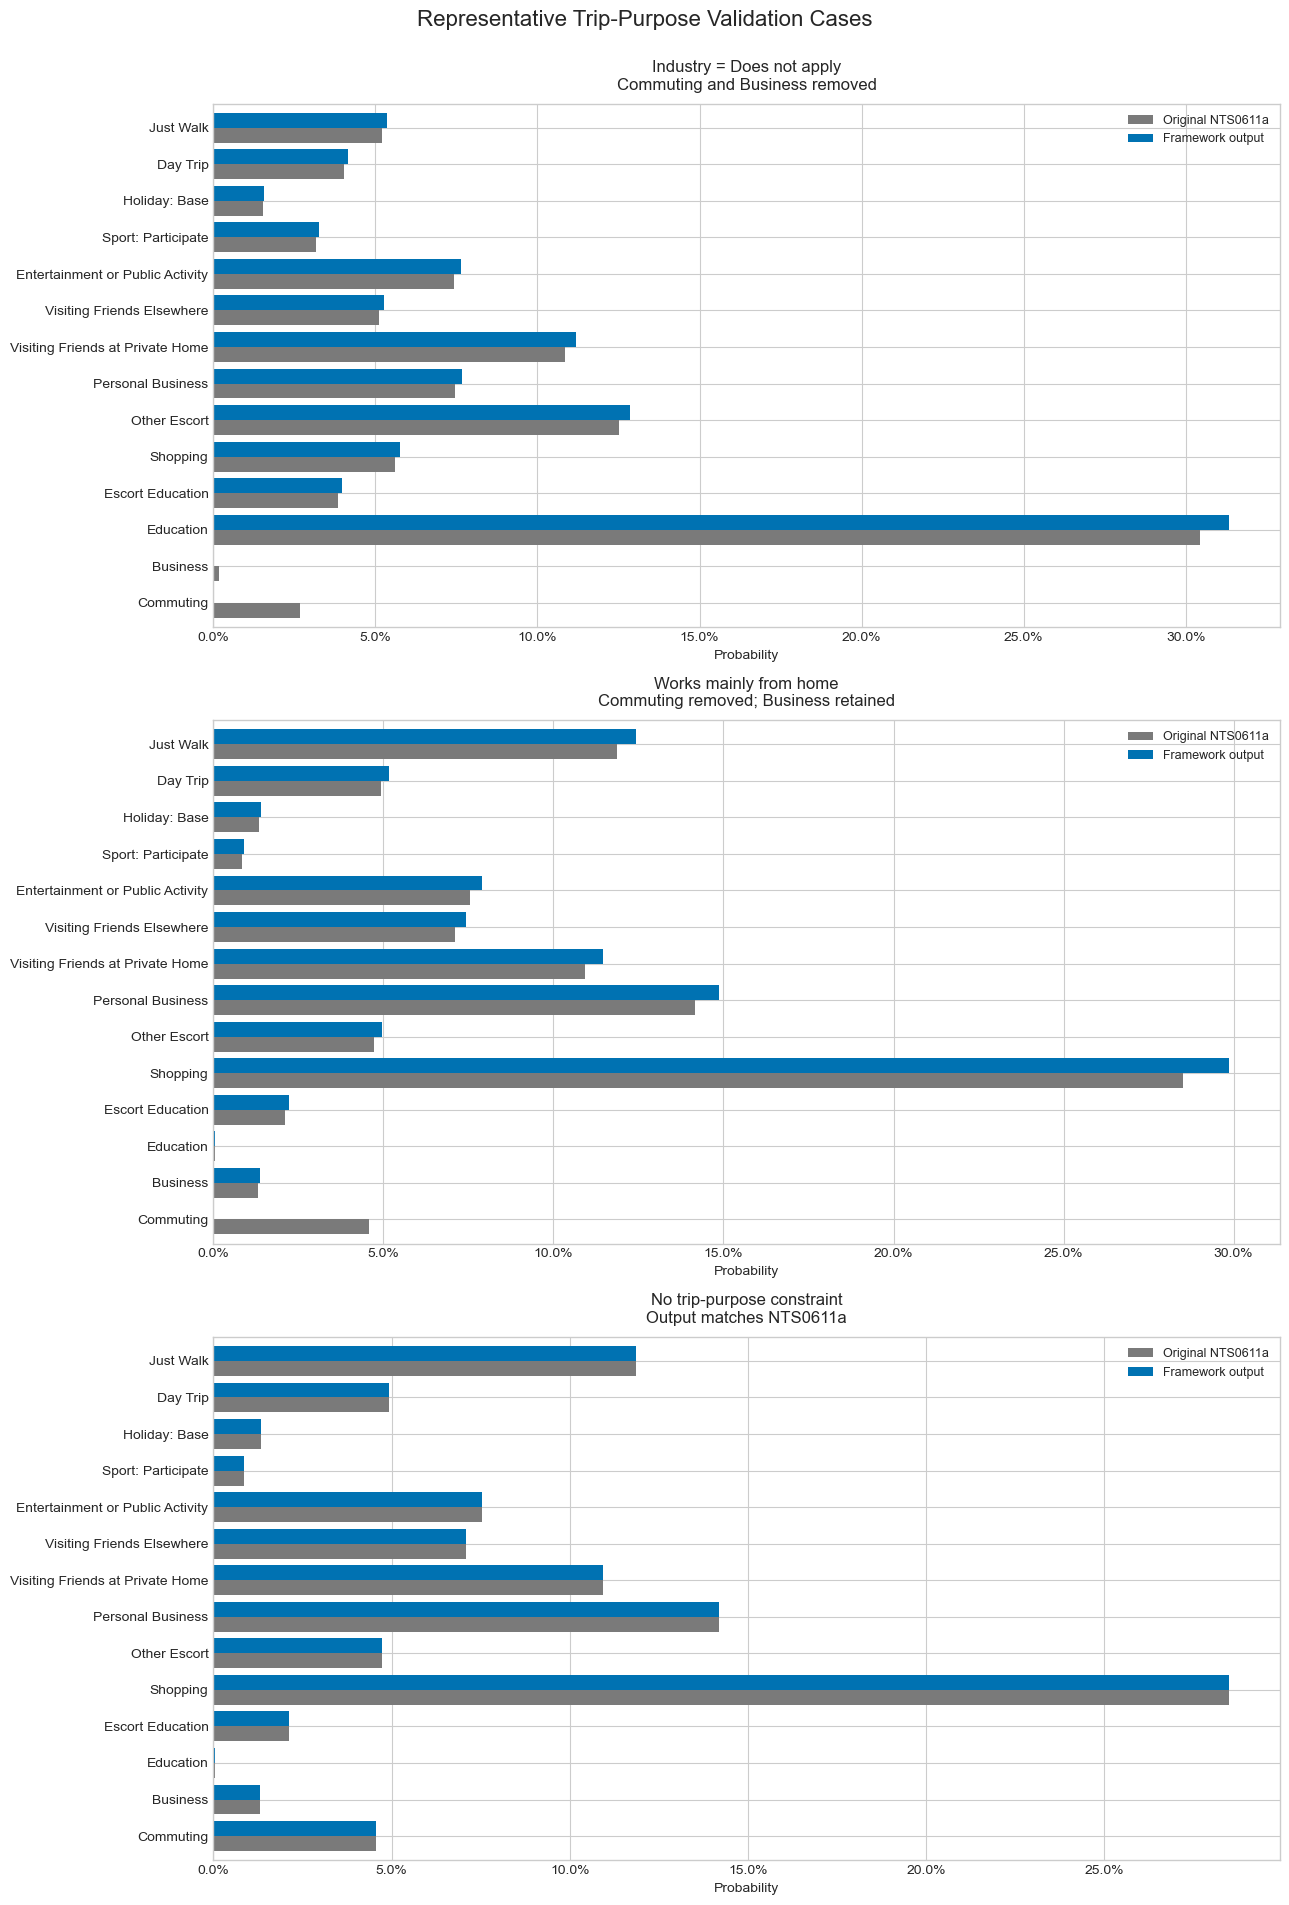

In [10]:
# AI Collaboration Record
# Tool: OpenAI Codex
# Human author and reviewer: Peter Jiang
# Prompt reference: See "AI Collaboration Record" near the start of this notebook.
# Prompt summary: Select and plot three representative trip-purpose cases for the Industry, work-from-home and no-trip-purpose-constraint conditions.

industry_case_id = select_case(
    case_summary["Industry constraint"]
    & ~case_summary["WFH constraint"],
)
wfh_case_id = select_case(
    case_summary["WFH constraint"]
    & ~case_summary["Industry constraint"],
)
no_trip_constraint_case_id = select_case(
    ~case_summary["Industry constraint"]
    & ~case_summary["WFH constraint"],
)

trip_purpose_cases = [
    (
        plot_data_by_case[industry_case_id],
        "Industry = Does not apply\nCommuting and Business removed",
    ),
    (
        plot_data_by_case[wfh_case_id],
        "Works mainly from home\nCommuting removed; Business retained",
    ),
    (
        plot_data_by_case[no_trip_constraint_case_id],
        "No trip-purpose constraint\nOutput matches NTS0611a",
    ),
]

figure, axes = plt.subplots(3, 1, figsize=(13, 19))
for axis, (case_data, title) in zip(axes, trip_purpose_cases):
    plot_distribution_comparison(
        axis,
        case_data["Source trip"],
        case_data["Framework trip"],
        title,
        "Original NTS0611a",
    )
figure.suptitle(
    "Representative Trip-Purpose Validation Cases",
    fontsize=16,
    y=1.0,
)
figure.tight_layout()

figure_1_path = (
    figure_output_directory
    / "figure_1_trip_purpose_representative_cases.png"
)
figure.savefig(figure_1_path, dpi=300, bbox_inches="tight")
generated_figure_paths.append(figure_1_path)
plt.show()
plt.close(figure)

### Figure 2. Start-time representative case

No implemented constraint changes the start-time distribution. The original NTS0502b and framework output for Shopping are therefore compared across all 24 hourly intervals. The lines should overlap completely.

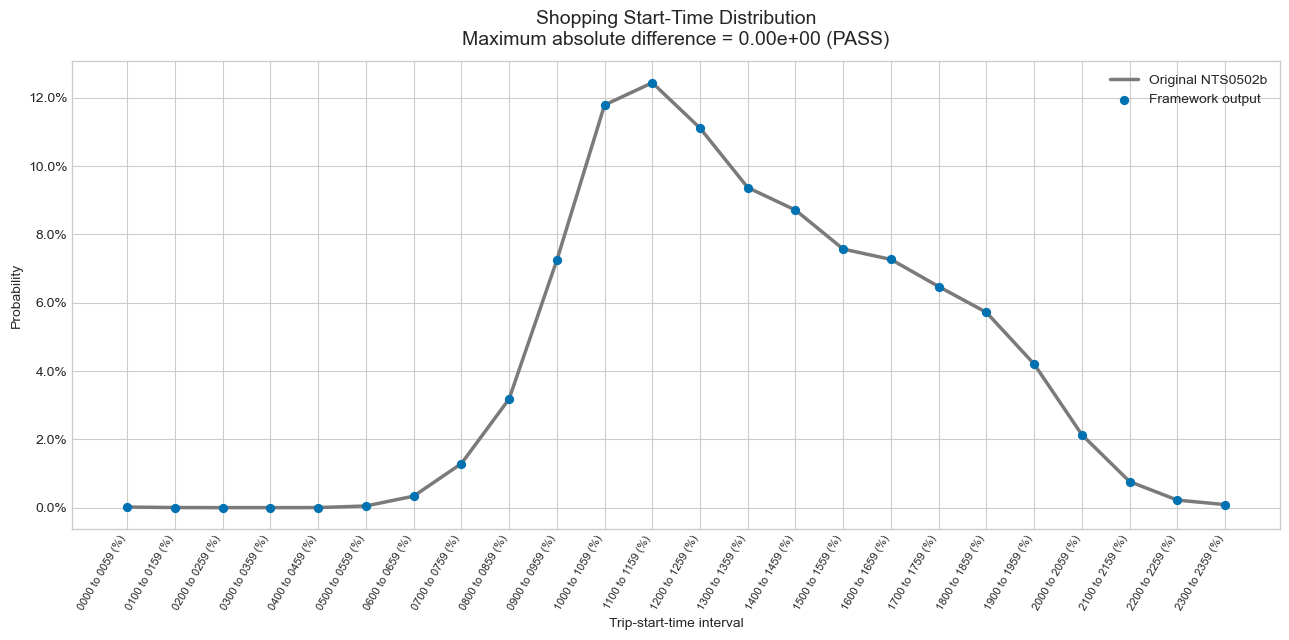

In [11]:
# AI Collaboration Record
# Tool: OpenAI Codex
# Human author and reviewer: Peter Jiang
# Prompt reference: See "AI Collaboration Record" near the start of this notebook.
# Prompt summary: Plot the original NTS0502b and framework Shopping start-time distributions for one representative profile.

start_time_case_id = no_trip_constraint_case_id
start_time_data = plot_data_by_case[start_time_case_id][
    "Conditioned"
]["Shopping"]
start_time_difference = float(
    (
        start_time_data["Source time"]
        - start_time_data["Framework time"]
    ).abs().max()
)

figure, axis = plt.subplots(figsize=(13, 6.5))
hour_positions = np.arange(
    len(start_time_data["Source time"])
)
axis.plot(
    hour_positions,
    start_time_data["Source time"].values,
    color=SERIES_COLOURS["Reference distribution"],
    linewidth=2.5,
    label="Original NTS0502b",
)
axis.scatter(
    hour_positions,
    start_time_data["Framework time"].values,
    color=SERIES_COLOURS["Framework output"],
    s=32,
    label="Framework output",
    zorder=3,
)
axis.set_xticks(hour_positions)
axis.set_xticklabels(
    start_time_data["Source time"].index,
    rotation=60,
    ha="right",
    fontsize=8,
)
axis.set_title(
    "Shopping Start-Time Distribution\n"
    f"Maximum absolute difference = {start_time_difference:.2e} (PASS)",
    fontsize=14,
    pad=12,
)
axis.set_xlabel("Trip-start-time interval")
axis.set_ylabel("Probability")
axis.yaxis.set_major_formatter(PercentFormatter(1.0))
axis.legend()
figure.tight_layout()

figure_2_path = (
    figure_output_directory
    / "figure_2_start_time_representative_case.png"
)
figure.savefig(figure_2_path, dpi=300, bbox_inches="tight")
generated_figure_paths.append(figure_2_path)
plt.show()
plt.close(figure)

### Figure 3. Travel-mode representative cases

Three Shopping travel-mode cases are shown. The first demonstrates that London-specific modes are removed for the Manchester case study. The second isolates the no-household-car constraint, and the third isolates the Children constraint. For the final two panels, the reference distribution has already had the Manchester study-area constraint applied, so the additional profile-specific removals are shown clearly.

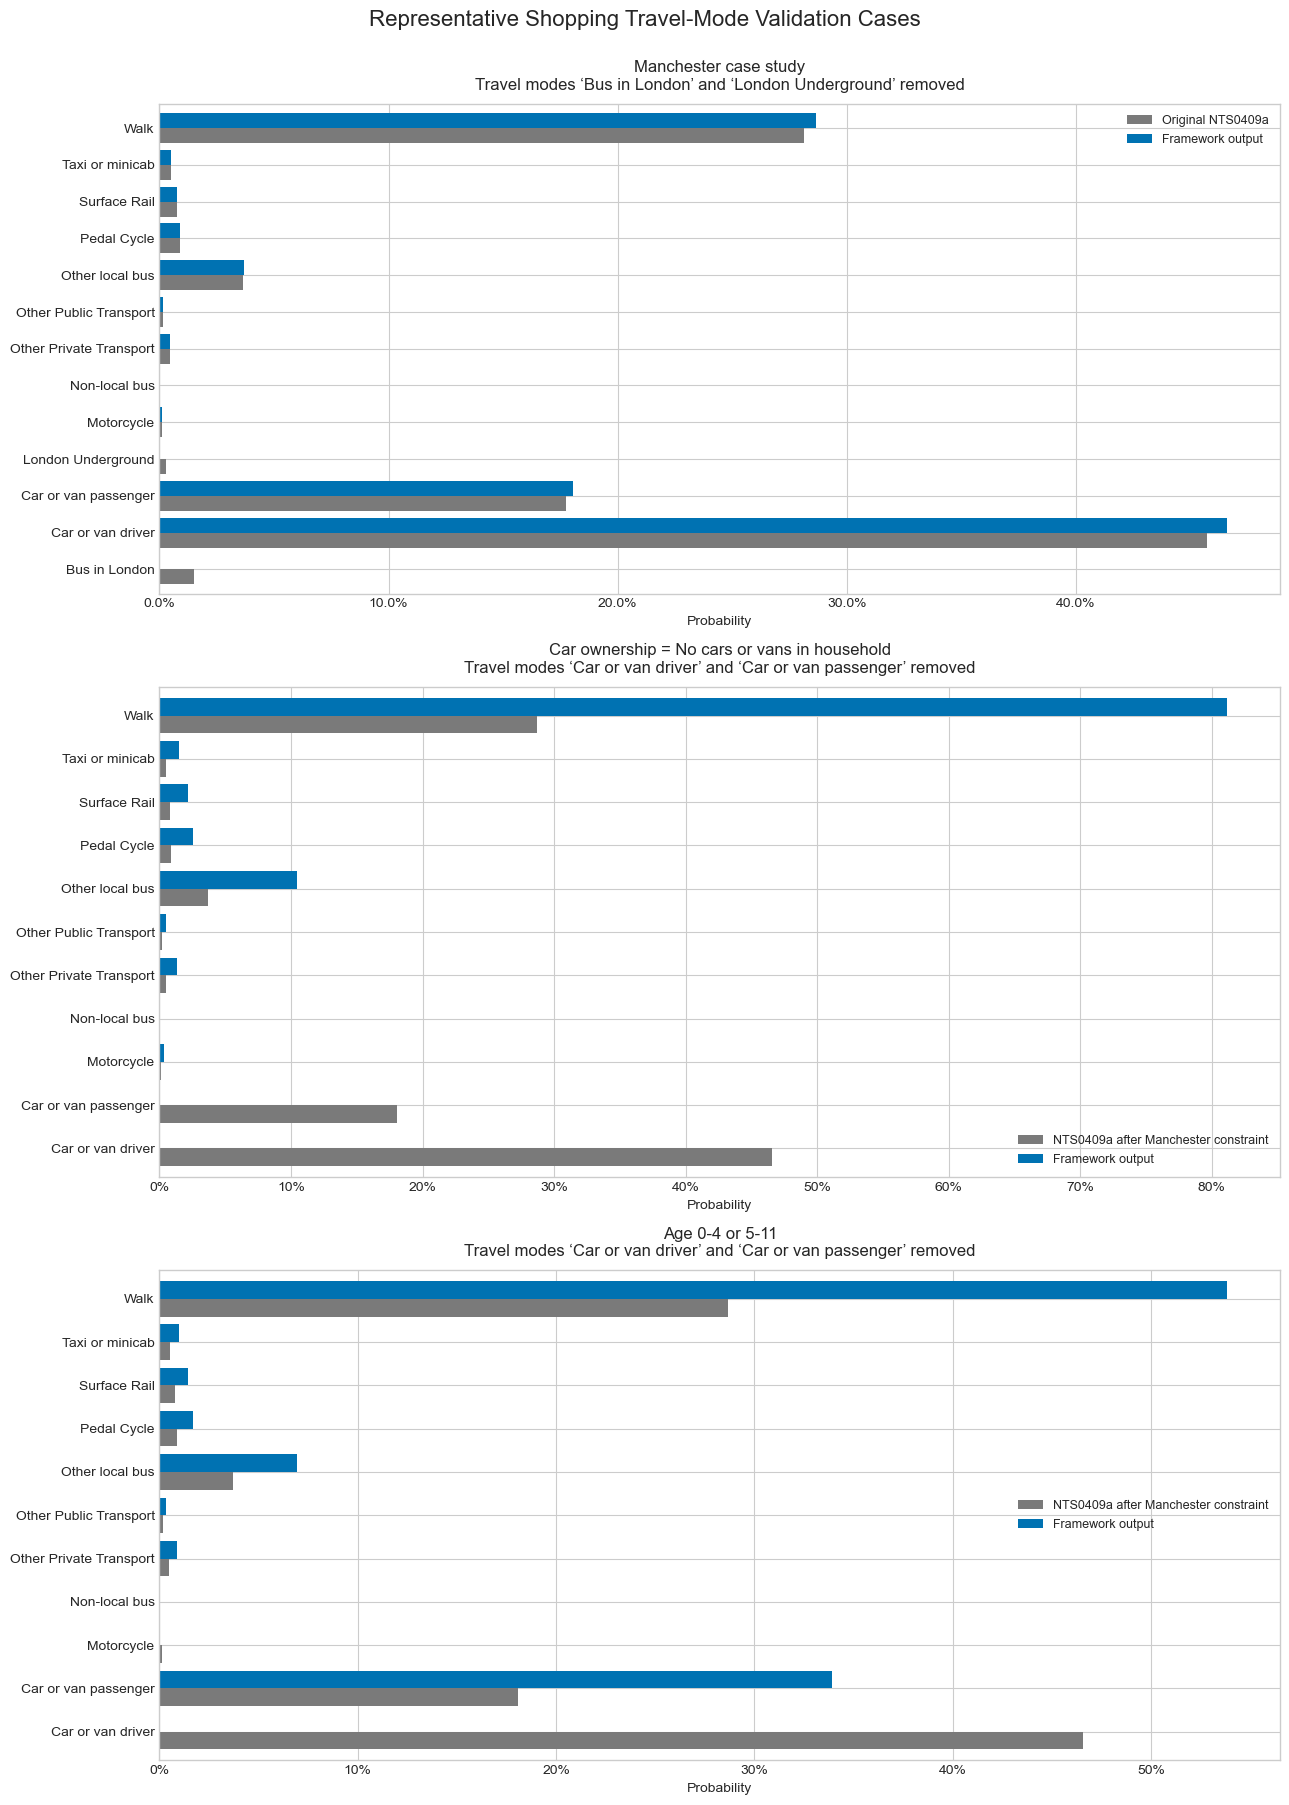

In [12]:
# AI Collaboration Record
# Tool: OpenAI Codex
# Human author and reviewer: Peter Jiang
# Prompt reference: See "AI Collaboration Record" near the start of this notebook.
# Prompt summary: Plot representative Manchester, no-household-car and young-age travel-mode cases using Shopping as one consistent trip purpose.

manchester_case_id = select_case(
    case_summary["Profile-specific constraint count"].eq(0),
    prefer_constraint_count=0,
)
no_car_case_id = select_case(
    case_summary["No-car constraint"]
    & ~case_summary["Children constraint"]
    & ~case_summary["Industry constraint"]
    & ~case_summary["WFH constraint"],
)
young_case_id = select_case(
    case_summary["Children constraint"]
    & ~case_summary["No-car constraint"],
)

manchester_mode = plot_data_by_case[manchester_case_id][
    "Conditioned"
]["Shopping"]
no_car_mode = plot_data_by_case[no_car_case_id][
    "Conditioned"
]["Shopping"]
young_mode = plot_data_by_case[young_case_id][
    "Conditioned"
]["Shopping"]

manchester_reference_mode = remove_and_renormalise(
    manchester_mode["Source mode"],
    LONDON_MODES_FOR_VALIDATION,
)

travel_mode_cases = [
    (
        manchester_mode["Source mode"],
        manchester_mode["Framework mode"],
        "Manchester case study\nTravel modes ‘Bus in London’ and ‘London Underground’ removed",
        "Original NTS0409a",
    ),
    (
        manchester_reference_mode,
        no_car_mode["Framework mode"],
        "Car ownership = No cars or vans in household\nTravel modes ‘Car or van driver’ and ‘Car or van passenger’ removed",
        "NTS0409a after Manchester constraint",
    ),
    (
        manchester_reference_mode,
        young_mode["Framework mode"],
        "Age 0-4 or 5-11\nTravel modes ‘Car or van driver’ and ‘Car or van passenger’ removed",
        "NTS0409a after Manchester constraint",
    ),
]

figure, axes = plt.subplots(3, 1, figsize=(13, 18))
for axis, (reference, output, title, reference_label) in zip(
    axes,
    travel_mode_cases,
):
    plot_distribution_comparison(
        axis,
        reference,
        output,
        title,
        reference_label,
    )
figure.suptitle(
    "Representative Shopping Travel-Mode Validation Cases",
    fontsize=16,
    y=1.0,
)
figure.tight_layout()

figure_3_path = (
    figure_output_directory
    / "figure_3_travel_mode_representative_cases.png"
)
figure.savefig(figure_3_path, dpi=300, bbox_inches="tight")
generated_figure_paths.append(figure_3_path)
plt.show()
plt.close(figure)

## 10. Final reproducible result

A complete PASS means:

- all retained rows satisfy the reported demographic constraints;
- all required behavioural conditions occur in the retained profile space;
- every unique output-relevant input combination matches the independently calculated expected distributions;
- every representative profile row is tested and no row has a validation violation;
- trip-purpose, start-time and travel-mode distributions contain the expected categories, contain finite non-negative probabilities and sum to one; and
- all three representative-case figures were exported after the numerical validation passed.

The validation establishes implementation correctness for the currently implemented rules. It does not establish real-world behavioural accuracy or prove that no additional constraints could be required.

In [13]:
# AI Collaboration Record
# Tool: OpenAI Codex
# Human author and reviewer: Peter Jiang
# Prompt reference: See "AI Collaboration Record" near the start of this notebook.
# Prompt summary: Verify all expected figure exports and print a concise final result suitable for the execution record.

expected_figure_names = {
    "figure_1_trip_purpose_representative_cases.png",
    "figure_2_start_time_representative_case.png",
    "figure_3_travel_mode_representative_cases.png",
}
exported_figure_names = {
    path.name
    for path in generated_figure_paths
    if path.exists() and path.stat().st_size > 0
}

missing_figure_exports = (
    expected_figure_names - exported_figure_names
)
if missing_figure_exports:
    raise AssertionError(
        "Expected figure exports are missing or empty: "
        f"{sorted(missing_figure_exports)}"
    )

print("CONSTRAINT AND DISTRIBUTION VALIDATION: PASS")
print(
    "Total representative profile rows:",
    f"{total_representative_rows:,}",
)
print(
    "Tested rows:",
    f"{tested_rows:,}",
)
print(
    "Rows with violations:",
    f"{rows_with_violations:,}",
)
print(
    "Unique behavioural input combinations executed:",
    f"{len(case_summary):,}",
)
print(
    "Figures exported to:",
    figure_output_directory,
)

CONSTRAINT AND DISTRIBUTION VALIDATION: PASS
Total representative profile rows: 2,147,608
Tested rows: 2,147,608
Rows with violations: 0
Unique behavioural input combinations executed: 92
Figures exported to: c:\Users\user\OneDrive - University of Stirling\Desktop\dissertation\mobility-modelling-framework\output\validation\constraint_distribution_validation\figures
